# Demo of the GTM on 10-Dimensional R-Vine-Copula Data

In this demonstration we show how the GTM can be used to learn a probability distribution from synthetic data sampled from a 10 dimensional R-Vine-Copula as done in our [Paper](https://arxiv.org/pdf/2503.17845) Section 4.
To sample synthetic copula data we use the [pyvinecopulib](https://github.com/vinecopulib/pyvinecopulib) library.
Fore more details on copulas we refer to the Book [Analyzing Dependent Data with Vine Copulas](https://link.springer.com/book/10.1007/978-3-030-13785-4) for an comprehensive introduction to copulas and vine copulas.

In [1]:
from gtm import *

# Sample Copulas Package
import pyvinecopulib as pv
# Helpers to generate specfific vines and analyze there conditional independencies
from demos.pyvinecopulib_simulation_helpers import *

# Other Stuff
import numpy as np
import torch
from torch.utils.data import DataLoader
from demos.dataset_helpers import Generic_Dataset
from sklearn.metrics import roc_auc_score, roc_curve

/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
set_seeds(1)

### 1. Sample Synthetic Copula Data and Compute Likelihoods

We sample data from a R-Vine-Copula and add Gaussian marginals. To create the Vine we use the functions `sample_random_pair_copulas`and `compute_conditional_dependence_table` from our helpers. Theses allow use to set independence copulas upon Tree 3 to add full conditional independencies as detailed in our Paper. The `df`contains a tables with the copulas, there parameters and there tree positions in a manner comparable to the conditional independence table later generated with the GTM.

In [3]:
D = 10  # dimension
rvine_structure = pv.RVineStructure.simulate(10, seeds=[1])
pair_copulas = sample_random_pair_copulas(D,Independence_tree=3)
vine_model = pv.Vinecop.from_structure(structure=rvine_structure, pair_copulas=pair_copulas)
df = compute_conditional_dependence_table(vine_model)
#df

creating a table to compare the true dependence structure later on to what the gtm learned

In [4]:

df_true_structure = df[["tree","edge","conditioned variables", "conditioned variable 1", "conditioned variable 2", "dependence", "var_row", "var_col"]]
df_true_structure_sub = df_true_structure[["var_row", "var_col", "dependence"]]
df_true_structure_sub.loc[:, "var_row"] = df_true_structure_sub["var_row"] - 1
df_true_structure_sub.loc[:, "var_col"] = df_true_structure_sub["var_col"] - 1


The `pyvinecopulib`package offers to plot the tree structures:

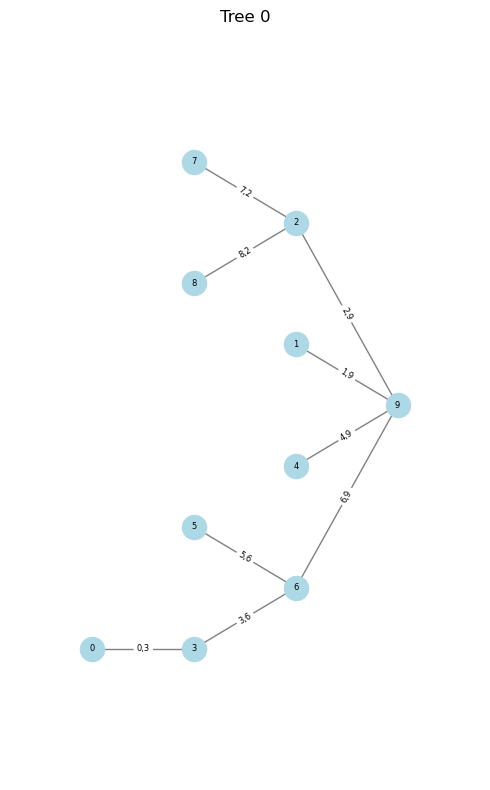

In [5]:
vine_model.plot(tree=[0])

In [ ]:
# Train
N_train = 100 #4000
simulated_data_uniform_train = vine_model.simulate(n=N_train, seeds=[1])
simulated_data_train = torch.distributions.Normal(0,1).icdf(torch.tensor(simulated_data_uniform_train)).float()

# Validate
N_validate = 25 #1000
simulated_data_uniform_validate = vine_model.simulate(n=N_validate, seeds=[1])
simulated_data_validate = torch.distributions.Normal(0,1).icdf(torch.tensor(simulated_data_uniform_validate)).float()

# Test
N_test = 20000
simulated_data_uniform_test = vine_model.simulate(n=N_test, seeds=[1])
simulated_data_test = torch.distributions.Normal(0,1).icdf(torch.tensor(simulated_data_uniform_test)).float()

In [7]:
simulated_data_uniform_train

array([[5.03133155e-01, 1.77768587e-01, 8.95171219e-01, 5.05425643e-01,
        5.34622940e-02, 7.74300141e-01, 6.19012086e-01, 9.31559614e-01,
        7.66499772e-01, 2.79797628e-01],
       [7.14522219e-01, 7.86447334e-01, 7.47068610e-01, 7.04124524e-01,
        6.79633894e-02, 6.47840129e-01, 8.70424632e-01, 5.89445465e-01,
        6.33556962e-01, 2.35961406e-01],
       [6.98054042e-01, 4.54715947e-01, 7.50580245e-01, 7.78986562e-01,
        2.67439567e-02, 4.98661029e-01, 7.15109419e-01, 5.39146564e-01,
        5.94759777e-01, 3.43641308e-01],
       [8.03291871e-02, 2.80840422e-01, 3.11065746e-01, 5.87023724e-02,
        9.26214183e-01, 5.88761901e-02, 3.01470906e-02, 3.97741335e-01,
        7.74980470e-02, 7.98369081e-01],
       [7.69715861e-01, 4.52295384e-01, 6.64704484e-01, 6.12787996e-01,
        3.16622405e-01, 2.26097941e-01, 7.35352516e-01, 7.92874878e-01,
        2.53888426e-01, 2.36530804e-01],
       [3.60560583e-01, 8.17750162e-01, 8.42473695e-01, 1.74002972e-01,
   

Notice we use Sklars Theorem to compute the density of the joint copula and Gaussian marginals density.

In [8]:
loglik_copula = np.log(vine_model.pdf(simulated_data_uniform_train))
log_marginals = torch.distributions.Normal(0,1).log_prob(simulated_data_train).sum(1)
loglik_true_train = torch.tensor(loglik_copula) + log_marginals

loglik_copula = np.log(vine_model.pdf(simulated_data_uniform_validate))
log_marginals = torch.distributions.Normal(0,1).log_prob(simulated_data_validate).sum(1)
loglik_true_validate = torch.tensor(loglik_copula) + log_marginals

loglik_copula = np.log(vine_model.pdf(simulated_data_uniform_test))
log_marginals = torch.distributions.Normal(0,1).log_prob(simulated_data_test).sum(1)
loglik_true_test = torch.tensor(loglik_copula) + log_marginals

We further estimate the copula on the synthetic data to get an oracle denisity estimator. Hence an estimator that knows the true underlying structure and merely estiamtes the model parameters.

In [9]:
copula_pv_est = vine_model
copula_pv_est.fit(simulated_data_uniform_train)
means = simulated_data_train.mean(0)
vars = simulated_data_train.var(0)

In [10]:
loglik_copula = np.log(copula_pv_est.pdf(simulated_data_uniform_train))
log_marginals = torch.distributions.Normal(means,vars).log_prob(simulated_data_train).sum(1)
loglik_true_est_train = torch.tensor(loglik_copula) + log_marginals

loglik_copula = np.log(copula_pv_est.pdf(simulated_data_uniform_validate))
log_marginals = torch.distributions.Normal(means,vars).log_prob(simulated_data_validate).sum(1)
loglik_true_est_validate = torch.tensor(loglik_copula) + log_marginals

loglik_copula = np.log(copula_pv_est.pdf(simulated_data_uniform_test))
log_marginals = torch.distributions.Normal(means,vars).log_prob(simulated_data_test).sum(1)
loglik_true_est_test = torch.tensor(loglik_copula) + log_marginals

The package is implemented to use Dataloaders for training. This is done to accommodate larger datasets trained batch wise as is common in deep learning and bioinformatics applications. Feel free to use the [`Generic_Dataset`](demos/dataset_helpers.py) class to easily adjust it to your data. For full data training, thus whithout batches simply seet the `batch_size` arguement in the `DataLoader` to the data size as we do in this example

In [11]:
# Create dataset and DataLoader
dataset_train = Generic_Dataset(simulated_data_train)
dataloader_train = DataLoader(dataset_train, batch_size=N_train)

dataset_validate = Generic_Dataset(simulated_data_validate)
dataloader_validate = DataLoader(dataset_validate, batch_size=N_validate)

In [12]:
simulated_data_train

tensor([[ 7.8537e-03, -9.2390e-01,  1.2545e+00,  1.3600e-02, -1.6122e+00,
          7.5308e-01,  3.0289e-01,  1.4875e+00,  7.2737e-01, -5.8344e-01],
        [ 5.6664e-01,  7.9415e-01,  6.6529e-01,  5.3630e-01, -1.4911e+00,
          3.7950e-01,  1.1284e+00,  2.2612e-01,  3.4129e-01, -7.1935e-01],
        [ 5.1881e-01, -1.1376e-01,  6.7632e-01,  7.6878e-01, -1.9310e+00,
         -3.3563e-03,  5.6837e-01,  9.8284e-02,  2.3981e-01, -4.0255e-01],
        [-1.4029e+00, -5.8035e-01, -4.9283e-01, -1.5658e+00,  1.4482e+00,
         -1.5643e+00, -1.8786e+00, -2.5920e-01, -1.4221e+00,  8.3581e-01],
        [ 7.3791e-01, -1.1986e-01,  4.2534e-01,  2.8659e-01, -4.7716e-01,
         -7.5176e-01,  6.2908e-01,  8.1644e-01, -6.6230e-01, -7.1751e-01],
        [-3.5696e-01,  9.0682e-01,  1.0047e+00, -9.3846e-01,  1.4290e+00,
          2.1200e+00,  5.3709e-01,  2.4669e+00,  2.7583e-01,  3.6208e-02],
        [-3.8541e-01, -4.6483e-01,  2.6312e-01, -3.6934e-01, -4.7577e-01,
         -7.2969e-01, -9.3492e-0

### 2. Define Model


In [13]:
import normflows as nf

In [14]:
# Set up model
def create_spline_flow(latent_size=10, 
                       number_of_layers=3,
                       hidden_layers=2, 
                       hidden_units=10, 
                       device="cpu"):
    torch.manual_seed(0)
    K = number_of_layers

    latent_size = latent_size
    hidden_units = hidden_units
    hidden_layers = hidden_layers

    flows = []
    for i in range(K):
        
        flows += [nf.flows.AutoregressiveRationalQuadraticSpline(latent_size, hidden_layers, hidden_units)]
        flows += [nf.flows.LULinearPermute(latent_size)]

    # Set base distribuiton
    q0 = nf.distributions.DiagGaussian(latent_size, trainable=False)
        
    # Construct flow model
    nfm = nf.NormalizingFlow(q0=q0, flows=flows)

    # Move model on GPU if available
    #enable_cuda = True
    #device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')
    nfm = nfm.to(device)
    
    return nfm

In [15]:
def create_maf_flow(latent_size=10, 
                    number_of_layers=3, 
                    hidden_layers=2, 
                    hidden_units=10, 
                    device="cpu"):
    torch.manual_seed(0)
    
    flows = []
    for i in range(number_of_layers):
              
        # Construct flow model
        flows += [nf.flows.MaskedAffineAutoregressive(
            features=latent_size,
            hidden_features=hidden_units,
            #context_features=None,
            num_blocks=hidden_layers,
            use_residual_blocks=False,
            #random_mask=False,
            #activation=F.relu,
            #dropout_probability=0.0,
            use_batch_norm=True,
        )]
        flows += [nf.flows.LULinearPermute(latent_size)]
        
    # Set base distribuiton
    q0 = nf.distributions.DiagGaussian(latent_size, trainable=False)
        
    # Construct flow model
    nfm = nf.NormalizingFlow(q0=q0, flows=flows)

    # Move model on GPU if available
    #enable_cuda = True
    #device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')
    nfm = nfm.to(device)
    
    return nfm

In [16]:
from tqdm import tqdm

In [17]:
# Train model

def train_nf(nfm, simulated_data_train, simulated_data_validate,
             early_stopping_patience =  30,
             max_iter = 2000,
             lr=1e-4, 
             weight_decay=1e-6,
             ):


    loss_hist = np.array([])
    loss_hist_val = np.array([])

    val_loss_min = torch.inf
    early_stopper=0
    optimizer = torch.optim.Adam(nfm.parameters(), lr=lr, weight_decay=weight_decay)
    for it in tqdm(range(max_iter)):
        optimizer.zero_grad()
        
        ## Get training samples
        #x_np, _ = make_moons(num_samples, noise=0.1)
        #x = torch.tensor(x_np).float().to(device)
        
        # Compute loss
        loss = nfm.forward_kld(simulated_data_train)
        
        # validation set based early stopping
        with torch.no_grad():
            val_loss_current = nfm.forward_kld(simulated_data_validate)
            if val_loss_current < val_loss_min:
                val_loss_min = val_loss_current
                best_model_dict = nfm.state_dict().copy()
                early_stopper = 0
            else:
                early_stopper += 1
                if early_stopper >= early_stopping_patience:
                    print(f"Early stopping at iteration {it} with validation loss {val_loss_min.item():.4f}")
                    break

        # Log loss
        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())
        loss_hist_val = np.append(loss_hist_val, val_loss_current.to('cpu').data.numpy())
        
        loss.backward()
        optimizer.step()
        
    nfm.load_state_dict(best_model_dict)
    
    return nfm, loss_hist, loss_hist_val

In [18]:
def hyperparameter_search(latent_size,number_of_layers_list=[3,4,5], hidden_layers=[2,3,4], hidden_units=[10,20,30], nf_model="maf"):
    results = []
    for number_of_layers in number_of_layers_list:
        for hidden_layer in hidden_layers:
            for hidden_unit in hidden_units:
                print(f"Training {nf_model.upper()} with {number_of_layers} layers, {hidden_layer} hidden layers and {hidden_unit} hidden units.")
                if nf_model == "maf":
                    nfm = create_maf_flow(number_of_layers=number_of_layers, latent_size=latent_size, hidden_layers=hidden_layer, hidden_units=hidden_unit)
                elif nf_model == "spline":
                    nfm = create_spline_flow(number_of_layers=number_of_layers, latent_size=latent_size, hidden_layers=hidden_layer, hidden_units=hidden_unit)
                nfm_trained, loss_hist, loss_hist_val = train_nf(nfm, simulated_data_train, simulated_data_validate,
                                                                 early_stopping_patience =  20,
                                                                 max_iter = 2000,
                                                                 lr=1e-3, 
                                                                 weight_decay=1e-5)
                results.append({
                    "number_of_layers": number_of_layers,
                    "hidden_layer": hidden_layer,
                    "hidden_unit": hidden_unit,
                    "model": nfm_trained,
                    "loss_val": loss_hist_val[-1]
                })
    return results


In [19]:
results = hyperparameter_search(latent_size=D,number_of_layers_list=[4,5,6,7], hidden_layers=[2,3,4], hidden_units=[5,10,20,30], nf_model="spline")

Training SPLINE with 4 layers, 2 hidden layers and 5 hidden units.


  4%|▍         | 88/2000 [00:00<00:17, 109.52it/s]


Early stopping at iteration 88 with validation loss 10.3974
Training SPLINE with 4 layers, 2 hidden layers and 10 hidden units.


  4%|▎         | 73/2000 [00:00<00:18, 105.54it/s]


Early stopping at iteration 73 with validation loss 10.3909
Training SPLINE with 4 layers, 2 hidden layers and 20 hidden units.


  3%|▎         | 59/2000 [00:00<00:18, 104.49it/s]


... (87 outputs left out)

  2%|▏         | 44/2000 [00:00<00:40, 48.82it/s]


Early stopping at iteration 44 with validation loss 10.2021
Training SPLINE with 7 layers, 4 hidden layers and 30 hidden units.


  2%|▏         | 42/2000 [00:00<00:39, 49.93it/s]

Early stopping at iteration 42 with validation loss 10.5313


/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_89450/2375928050.py:7: FutureWarning: The provided callable <function min at 0x105d02ca0> is currently using DataFrameGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  results_df_pivot = results_df.pivot_table(


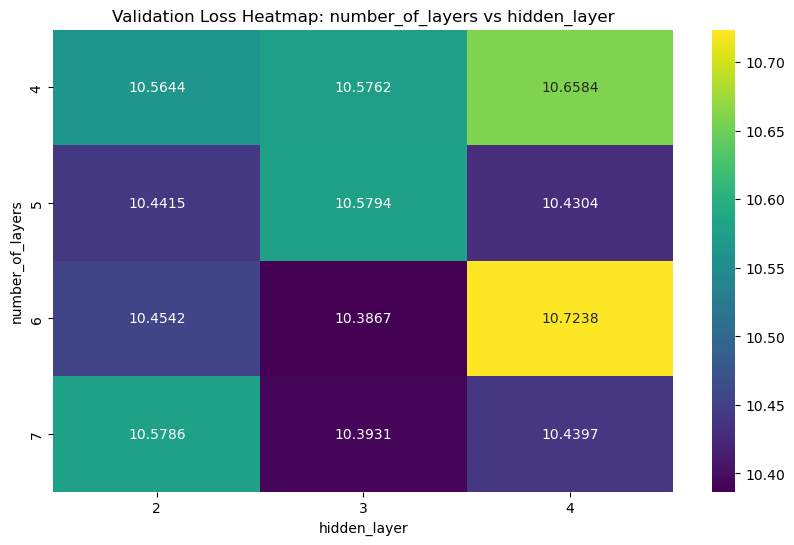

In [20]:
# Suppose 'results' is a list of dicts with keys "hidden_layer", "hidden_unit", "loss_val"
hp1 = "number_of_layers"
hp2 = "hidden_layer"
results_df = pd.DataFrame(results)

# Pivot the dataframe: rows=hp1, columns=hp2, values=loss
results_df_pivot = results_df.pivot_table(
    index=hp1,
    columns=hp2,
    values="loss_val",
    aggfunc=np.min  # or np.min, np.max, etc.
)  # Use mean if there are multiple entries for the same combination

# Plot
plt.figure(figsize=(10,6))
sns.heatmap(results_df_pivot, annot=True, fmt=".4f", cmap="viridis")
plt.title(f'Validation Loss Heatmap: {hp1} vs {hp2}')
plt.ylabel(hp1)
plt.xlabel(hp2)
plt.show()

/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_89450/3863500292.py:7: FutureWarning: The provided callable <function min at 0x105d02ca0> is currently using DataFrameGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  results_df_pivot = results_df.pivot_table(


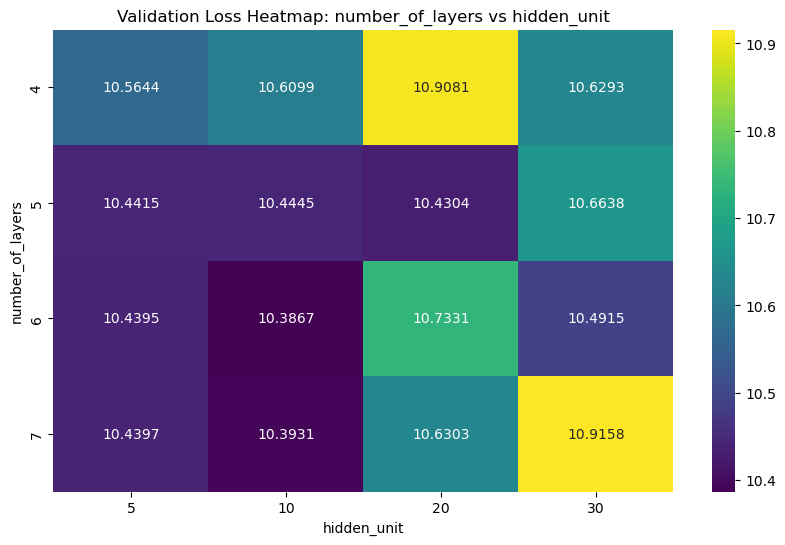

In [21]:
# Suppose 'results' is a list of dicts with keys "hidden_layer", "hidden_unit", "loss_val"
hp1 = "number_of_layers"
hp2 = "hidden_unit"
results_df = pd.DataFrame(results)

# Pivot the dataframe: rows=hp1, columns=hp2, values=loss
results_df_pivot = results_df.pivot_table(
    index=hp1,
    columns=hp2,
    values="loss_val",
    aggfunc=np.min  # or np.min, np.max, etc.
)  # Use mean if there are multiple entries for the same combination

# Plot
plt.figure(figsize=(10,6))
sns.heatmap(results_df_pivot, annot=True, fmt=".4f", cmap="viridis")
plt.title(f'Validation Loss Heatmap: {hp1} vs {hp2}')
plt.ylabel(hp1)
plt.xlabel(hp2)
plt.show()

In [22]:
pd.DataFrame(results).sort_values("loss_val")

,number_of_layers,hidden_layer,hidden_unit,model,loss_val
29,6,3,10,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.386675
41,7,3,10,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.393148
22,5,4,20,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.430393
28,6,3,5,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.439458
44,7,4,5,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.439668
12,5,2,5,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.441536
13,5,2,10,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.444537
25,6,2,10,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.454167
40,7,3,5,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.475865
27,6,2,30,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.491510


In [23]:
nfm = create_maf_flow(features=10, number_of_layers=3, hidden_features=10, num_blocks=2, use_residual_blocks=False, device="cpu")

TypeError: create_maf_flow() got an unexpected keyword argument 'features'

In [24]:
nfm = create_spline_flow(number_of_layers=3, latent_size=10, hidden_layers=2, hidden_units=10, device="cpu")

In [25]:
nfm, loss_hist, loss_hist_val = train_nf(nfm, simulated_data_train, simulated_data_validate,
             early_stopping_patience =  20,
             max_iter = 4000,
             lr=1e-2, 
             weight_decay=1e-3,
             )

  1%|          | 26/4000 [00:00<00:30, 129.95it/s]

Early stopping at iteration 26 with validation loss 10.7597


In [26]:
pd.DataFrame(results).sort_values("loss_val")

,number_of_layers,hidden_layer,hidden_unit,model,loss_val
29,6,3,10,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.386675
41,7,3,10,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.393148
22,5,4,20,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.430393
28,6,3,5,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.439458
44,7,4,5,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.439668
12,5,2,5,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.441536
13,5,2,10,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.444537
25,6,2,10,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.454167
40,7,3,5,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.475865
27,6,2,30,NormalizingFlow(\n (q0): DiagGaussian()\n (f...,10.491510


In [27]:
nfm = pd.DataFrame(results).sort_values("loss_val")["model"][0]

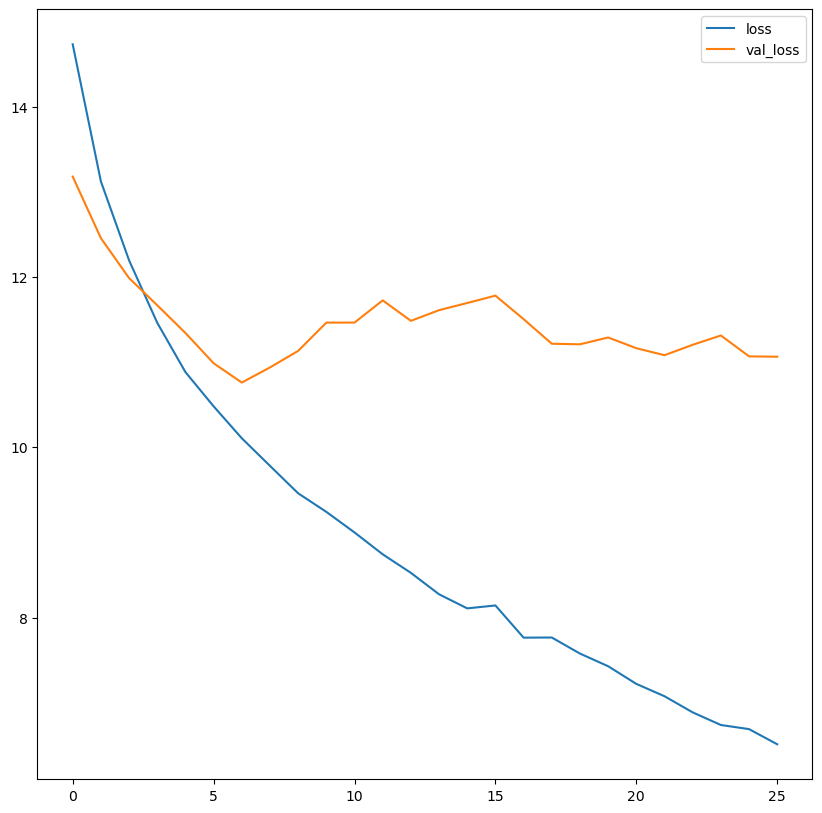

In [28]:
# Plot loss
plt.figure(figsize=(10, 10))
plt.plot(loss_hist, label='loss')
plt.plot(loss_hist_val, label='val_loss')
plt.legend()
plt.show()

The GTM class contains a number of plotting functions so that standard analysis can be done soley with the model:

In [ ]:
#model.plot_densities(simulated_data_train, x_lim=[-4,4], y_lim=[-4,4])

In [ ]:
#model.plot_marginals(simulated_data_train)

### 3. Hyperparameter Tune and Train Model

To find the optimal penalties one uses the `hyperparameter_tune_penalties` function. Then using the optimal penalties one can train the model.

The training can be done by pretraining the marginal transformations with `pretrain_tranformation_layer` and then training jointly with `train`.
In general empirically we found that pretraining reduces training time and improves results allthough direct joint training also works.

Hyperparameter tuning can be done for the penalties `penvalueridge, penfirstridge , pensecondridge, ctm_pensecondridge, lambda_penalty_params` by passing the arguement `"sample"`.
If a fixed number is passed, typically zero, then for that penalty no hyperparameter drawing is done and the fixed values is used.


### 4. Compare to Benchmarks

We compare the learned GTM to a Gaussian Approximation and the Oracle Model. We expect the GTM to lie between these two in terms of approximation the true underlying distribution.
We measure this by means of the Kullback Leibler Divergence which we approximate on the test set which is equivalent to the log likelihood ratio between the true distribution and an approximation of it..

In [29]:
log_likelihood_train_maf = nfm.log_prob(simulated_data_train)
log_likelihood_validate_maf = nfm.log_prob(simulated_data_validate)
log_likelihood_test_maf = nfm.log_prob(simulated_data_test)

In [30]:
# estimate the Multivariate Normal Distribution as Model
mean_mvn_model = simulated_data_train.mean(0)
cov_mvn_model = simulated_data_train.T.cov()
mvn_model = torch.distributions.MultivariateNormal(loc=mean_mvn_model, covariance_matrix=cov_mvn_model)
log_likelihood_train_gaussian = mvn_model.log_prob(simulated_data_train)
log_likelihood_validate_gaussian = mvn_model.log_prob(simulated_data_validate)
log_likelihood_test_gaussian = mvn_model.log_prob(simulated_data_test)


In [31]:
print("KLD MAF      Train Data: ",np.round(torch.mean(loglik_true_train - log_likelihood_train_maf).item(),4) )
print("KLD Gaussian Train Data: ",np.round(torch.mean(loglik_true_train - log_likelihood_train_gaussian).item(),4) )
print("KLD Copula   Train Data: ",np.round(torch.mean(loglik_true_train - loglik_true_est_train).item(),4) )

print("KLD MAF      Test  Data: ",np.round(torch.mean(loglik_true_test - log_likelihood_test_maf).item(),4) )
print("KLD Gaussian Test  Data: ",np.round(torch.mean(loglik_true_test - log_likelihood_test_gaussian).item(),4) )
print("KLD Copula   Test  Data: ",np.round(torch.mean(loglik_true_test - loglik_true_est_test).item(),4) )

KLD MAF      Train Data:  -0.4079
KLD Gaussian Train Data:  2.3796
KLD Copula   Train Data:  0.0699
KLD MAF      Test  Data:  3.7198
KLD Gaussian Test  Data:  3.4533
KLD Copula   Test  Data:  0.9488


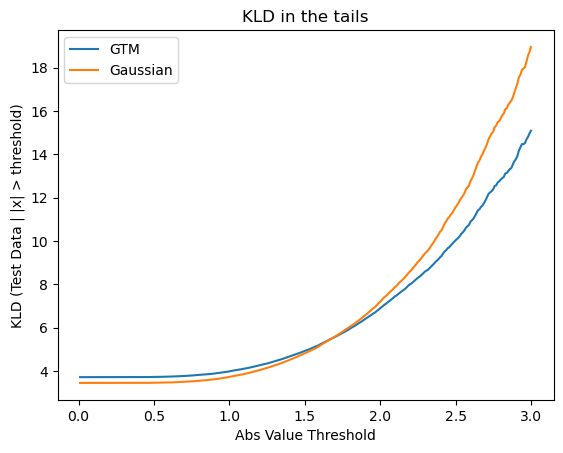

In [73]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Example thresholds (change as needed)
thresholds = np.linspace(0, 3, 300)[1:]

kld_gtm = []
kld_gaussian = []

for t in thresholds:
    # For multi-dimensional data, use 'any' or 'all' as needed:
    mask = (simulated_data_test.abs().numpy() > t).any(1)

    if mask.sum() == 0:
        kld_gtm.append(np.nan)
        kld_gaussian.append(np.nan)
        continue

    # Mask the loglik vectors using selected test points
    kld_gtm_val = torch.mean((loglik_true_test - log_likelihood_test_maf)[mask]).item()
    kld_gaussian_val = torch.mean((loglik_true_test - log_likelihood_test_gaussian)[mask]).item()
    kld_gtm.append(kld_gtm_val)
    kld_gaussian.append(kld_gaussian_val)

# Plot
plt.plot(thresholds, kld_gtm, label='GTM')
plt.plot(thresholds, kld_gaussian, label='Gaussian')
plt.xlabel('Abs Value Threshold')
plt.ylabel('KLD (Test Data | |x| > threshold)')
plt.title('KLD in the tails')
plt.legend()
plt.show()

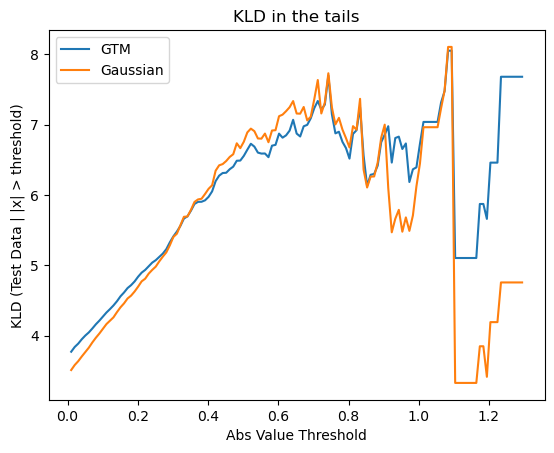

In [74]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Example thresholds (change as needed)
thresholds = np.linspace(0, 3, 300)[1:]

kld_gtm = []
kld_gaussian = []

for t in thresholds:
    # For multi-dimensional data, use 'all' as needed:
    mask = (simulated_data_test.abs().numpy() > t).all(1)  # for threshold on all dimension

    if mask.sum() == 0:
        kld_gtm.append(np.nan)
        kld_gaussian.append(np.nan)
        continue

    # Mask the loglik vectors using selected test points
    kld_gtm_val = torch.mean((loglik_true_test - log_likelihood_test_maf)[mask]).item()
    kld_gaussian_val = torch.mean((loglik_true_test - log_likelihood_test_gaussian)[mask]).item()
    kld_gtm.append(kld_gtm_val)
    kld_gaussian.append(kld_gaussian_val)

# Plot
plt.plot(thresholds, kld_gtm, label='GTM')
plt.plot(thresholds, kld_gaussian, label='Gaussian')
plt.xlabel('Abs Value Threshold')
plt.ylabel('KLD (Test Data | |x| > threshold)')
plt.title('KLD in the tails')
plt.legend()
plt.show()

### 5. Evaluate and Plot GTM Results

We evaluate the model further by showing how to generate synthetic samples, plot the conditional correlation patterns as well as identify conditional independencies.
To Do so we start by evaluate the conditional indepenedence_relationships. By computing the table we compute pseudo correlation matrix based conditional independence metrics and likelihood based conditional independence metrics such as the iae and the kld. For more details on these see the paper. This computation may take some time as it computes quadratures under the hood, see the algorithm 1 in the paper.


In [ ]:
device = "cpu"
num_points_quad=10
min_val=-5
max_val=5
evaluation_data_type="data"
model = nfm
model.device = device
evaluation_data = simulated_data_train

In [ ]:
from gtm.gtm_plots_analysis.compute_conditional_independence_kld_v2 import compute_conditional_independence_kld_v2, setup_quadrature, compute_single_var_marginals, compute_pair_metrics, compute_two_var_marginal

In [ ]:
def compute_single_var_marginals(model, data, quad_x, quad_w, batch_size=None):

    N, D = data.shape
    Q = quad_x.shape[0]
    single_var_marginals = torch.zeros(D, N, device=model.device)

    # log weights computed once
    log_w = torch.log(quad_w)  # shape (Q,)

    with tqdm(total=D, desc="Single var marginals", position=1, leave=False) as pbar:
        for col_idx in range(D):

            if batch_size is None:
                batch_size_eff = N
            else:
                batch_size_eff = batch_size

            marginal_col = torch.zeros(N, device=model.device)

            for start_idx in range(0, N, batch_size_eff):
                end_idx = min(start_idx + batch_size_eff, N)
                batch_n = end_idx - start_idx

                # build chunk on the fly
                data_chunk = data[start_idx:end_idx]                                          # shape (batch_n, D)
                expanded_data_chunk = data_chunk.unsqueeze(1).expand(
                    batch_n, Q, D
                ).reshape(batch_n * Q, D).clone()                                             # shape (batch_n*Q, D)

                # expand quad points and log weights
                # (Q,) -> (batch_n, Q) -> (batch_n*Q,)
                expanded_points     = quad_x.unsqueeze(0).expand(batch_n, Q).reshape(batch_n * Q)   # shape (batch_n*Q,)
                expanded_log_w      = log_w.unsqueeze(0).expand(batch_n, Q).reshape(batch_n * Q)    # shape (batch_n*Q,)

                # replace column
                expanded_data_chunk[:, col_idx] = expanded_points

                # log likelihood
                ll_chunk = model.log_prob(
                    expanded_data_chunk
                )                                                                              # shape (batch_n*Q,)

                # log-sum-exp over Q points
                # ll_chunk + log_w: shape (batch_n*Q,) -> (batch_n, Q)
                log_integrand = (ll_chunk + expanded_log_w).view(batch_n, Q)                  # shape (batch_n, Q)
                marginal_col[start_idx:end_idx] = torch.logsumexp(log_integrand, dim=1)       # shape (batch_n,)

            single_var_marginals[col_idx] = marginal_col
            pbar.update(1)

    return single_var_marginals  # shape (D, N) - already in log space


def compute_two_var_marginal(model, data, col_idx_1, col_idx_2, 
                             #quad_x, quad_w, 
                             quad_x_2d, log_quad_w_2d,
                             batch_size=None):

    N, D = data.shape
    Q2 = quad_x_2d.shape[0]

    ## construct 2D grid once
    #points_i = quad_x.unsqueeze(1).expand(Q, Q).reshape(-1)           # shape (Q²,)
    #points_j = quad_x.unsqueeze(0).expand(Q, Q).reshape(-1)           # shape (Q²,)
    #points   = torch.stack([points_i, points_j], dim=1)                # shape (Q², 2)
#
    ## 2D log weights via outer sum in log space
    #log_w    = torch.log(quad_w)                                       # shape (Q,)
    #log_w_2d = (log_w.unsqueeze(1) + log_w.unsqueeze(0)).reshape(-1)  # shape (Q²,)
    
    points = quad_x_2d.to(model.device)  # shape (Q², 2)
    log_w_2d = log_quad_w_2d.to(model.device)

    if batch_size is None:
        batch_size_eff = N
    else:
        batch_size_eff = batch_size

    marginal = torch.zeros(N, device=model.device)

    for start_idx in range(0, N, batch_size_eff):
        end_idx = min(start_idx + batch_size_eff, N)
        batch_n = end_idx - start_idx

        # build chunk on the fly
        data_chunk = data[start_idx:end_idx]                                               # shape (batch_n, D)
        expanded_data_chunk = data_chunk.unsqueeze(1).expand(
            batch_n, Q2, D
        ).reshape(batch_n * Q2, D).clone()                                                 # shape (batch_n*Q², D)

        # expand points and log weights
        expanded_points  = points.unsqueeze(0).expand(
            batch_n, Q2, 2
        ).reshape(batch_n * Q2, 2)                                                         # shape (batch_n*Q², 2)
        expanded_log_w   = log_w_2d.unsqueeze(0).expand(
            batch_n, Q2
        ).reshape(batch_n * Q2)                                                            # shape (batch_n*Q²,)

        # replace columns
        expanded_data_chunk[:, col_idx_1] = expanded_points[:, 0]
        expanded_data_chunk[:, col_idx_2] = expanded_points[:, 1]

        # log likelihood
        ll_chunk = model.log_prob(
            expanded_data_chunk
        )                                                                                   # shape (batch_n*Q²,)

        # log-sum-exp over Q² points
        log_integrand = (ll_chunk + expanded_log_w).view(batch_n, Q2)                     # shape (batch_n, Q²)
        marginal[start_idx:end_idx] = torch.logsumexp(log_integrand, dim=1)               # shape (batch_n,)

    return marginal  # shape (N,) - already in log space


In [ ]:
N, D = evaluation_data.shape
device = "cpu"
# move data to device once
evaluation_data = evaluation_data.to(device)

pairs = [(i, j) for i in range(D) for j in range(i + 1, D)] # all pairs
# -----------------------------------------------------------------
# Step 1: Setup quadrature points and weights once
# -----------------------------------------------------------------
#with tqdm(total=D, desc="Setup", position=0) as setup_pbar:
#setup_pbar.set_description("Setting up quadrature points")
print("Setting up quadrature points")
quad_x, quad_w, quad_x_2d, log_quad_w_2d = setup_quadrature(
    num_points=num_points_quad,
    min_val=min_val,
    max_val=max_val,
    device=device,
)

# quad_x: shape (Q,)
# quad_w: shape (Q,)
#setup_pbar.update(1)
# -----------------------------------------------------------------
# Step 2: Compute model log likelihood on data once
# -----------------------------------------------------------------
#setup_pbar.set_description("Computing model log likelihood")
print("Computing model log likelihood")
model_ll = model.log_prob(evaluation_data)  # shape (N,)
#setup_pbar.update(1)
# -----------------------------------------------------------------
# Step 3: Compute all D single variable marginals once
# -----------------------------------------------------------------
#setup_pbar.set_description("Computing single variable marginals")
print(("Computing single variable marginals"))
single_var_marginals = compute_single_var_marginals(
    model=model,
    data=evaluation_data,
    quad_x=quad_x,
    quad_w=quad_w,
    #batch_size=batch_size,
)
# single_var_marginals: shape (D, N)
#setup_pbar.update(1)
#setup_pbar.set_description("Setup complete")
#setup_pbar.update(1)
# -----------------------------------------------------------------
# Step 4: Loop over pairs, compute two var marginal and metrics
# -----------------------------------------------------------------
results = []
results = [
    {
        "var_col": col_idx_1,
        "var_row": col_idx_2,
        **dict(zip(["kld", "iae"], compute_pair_metrics(
            model_ll=model_ll,
            single_var_marginals=single_var_marginals,
            two_var_marginal=compute_two_var_marginal(
                model=model,
                data=evaluation_data,
                col_idx_1=col_idx_1,
                col_idx_2=col_idx_2,
                quad_x_2d=quad_x_2d,
                log_quad_w_2d=log_quad_w_2d,
                batch_size=None,
            ),
            col_idx_1=col_idx_1,
            col_idx_2=col_idx_2,
            evaluation_data_type=evaluation_data_type,
        )))
    }
    for col_idx_1, col_idx_2 in tqdm(pairs, desc="Computing pair metrics", position=0, leave=True)
]
# -----------------------------------------------------------------
# Step 5: Assemble results
# -----------------------------------------------------------------
results_df = pd.DataFrame(results)

Setting up quadrature points
Computing model log likelihood
Computing single variable marginals


Computing pair metrics: 100%|██████████| 45/45 [00:01<00:00, 28.43it/s]


In [ ]:
results_df

,var_col,var_row,kld,iae
0,0,1,0.429244,0.285723
1,0,2,0.658916,0.293764
2,0,3,0.263139,0.226151
3,0,4,0.227123,0.157697
4,0,5,0.548395,0.226225
5,0,6,0.140872,0.313388
6,0,7,0.264787,0.215448
7,0,8,0.300223,0.173736
8,0,9,0.516014,0.295976
9,1,2,0.709590,0.374731


### relativ hessian approach

In [ ]:
from gtm.gtm_plots_analysis.compute_normalised_hessian_metric import pairwise_blockwise_nuclear_normalize_vectorised
from gtm.gtm_plots_analysis.compute_precision_matrix_summary_statistics import compute_precision_matrix_summary_statistics

In [65]:
from gtm.gtm_plots_analysis.compute_normalised_hessian_metric import pairwise_blockwise_nuclear_normalize_vectorised
from gtm.gtm_plots_analysis.compute_precision_matrix_summary_statistics import compute_precision_matrix_summary_statistics

def compute_local_loglikelihood_hessian(model,
                              y):
        
        samples = y.detach().clone().requires_grad_(True)  # (N, D)
        N, D = samples.shape

        score = model.log_prob(samples).sum()
        grad = torch.autograd.grad(score, samples, create_graph=True)[0]  # Shape: (1, D)

        hessian_vmap = [torch.autograd.grad(grad.sum(0)[d], samples, create_graph=True)[0] for d in range(D)]  # Shape: (1, D)

        hessian_vmap = torch.stack(hessian_vmap).permute(1, 0, 2)
        
        return hessian_vmap
    
    
def compute_conditional_independence_table_local_relative_hessian(model,y=None,
                                                                  evaluation_data_type="data",
                                                                  sample_size=1000,
                                                                  min_val=-torch.inf,
                                                                  max_val=+torch.inf):
    
    if evaluation_data_type == "data":
        if y==None:
            print("if evaluation_data_type=data then you need to pass data using arguement y.")
        else:
            evaluation_data=y
    elif evaluation_data_type == "samples_from_model":
        evaluation_data = model.sample(sample_size)[0].detach()
        # only data within the bound otherwise drop datapoints
        bool_mask = (evaluation_data >= min_val) & (evaluation_data <= max_val)
        if bool_mask.all(dim=1).sum() < sample_size:
            print(f"Warning: Only {bool_mask.all(dim=1).sum().item()} samples are within the specified bounds. Others are dropped.")
        evaluation_data = evaluation_data[bool_mask.all(dim=1)]
    
    hessians = compute_local_loglikelihood_hessian(nfm,
                              evaluation_data)
    
    normed_hessian = pairwise_blockwise_nuclear_normalize_vectorised(hessians, eps=1e-12)
    
    table = compute_precision_matrix_summary_statistics(normed_hessian.detach())
    
    table["normed_hessian_abs_mean"] = table["abs_mean"]
    
    table = table[[
            "var_row",
            "var_col",
            "normed_hessian_abs_mean",
        ]]
    
    return table

In [47]:
nfm.sample(100)[0].size()

torch.Size([100, 10])

In [40]:
hessians = compute_local_loglikelihood_hessian(nfm,
                              simulated_data_train)

In [42]:
normed_hessian = pairwise_blockwise_nuclear_normalize_vectorised(hessians, eps=1e-12)

In [51]:
table_ci_normed_hessian = compute_conditional_independence_table_local_relative_hessian(nfm,
                                                              y=simulated_data_train,
                                                                  evaluation_data_type="data",
                                                                  sample_size=1000,
                                                                  min_val=-torch.inf,
                                                                  max_val=+torch.inf)

In [66]:
table_ci_normed_hessian = compute_conditional_independence_table_local_relative_hessian(nfm,
                                                              y=None,
                                                                  evaluation_data_type="samples_from_model",
                                                                  sample_size=10000,
                                                                  min_val=-torch.inf,
                                                                  max_val=+torch.inf)

### 6. Identifying the Conditional Independence Graph

We compare the true known conditional independence Graph to the one learned by the GTM. To do so we first merge the true structure table with our learned one.

In [54]:
merged_ci_tables = pd.merge(
    results_df,
    df_true_structure_sub,
    on=["var_row", "var_col"]
)


KeyError: 'var_row'

In [69]:
merged_ci_tables2 = pd.merge(
    table_ci_normed_hessian,
    df_true_structure_sub,
    on=["var_row", "var_col"]
)


take a look at the table and sort by some idicator such as iae.

In [140]:
#merged_ci_tables.sort_values("iae",ascending=False) 

with the spearman and pearson correlations one can see how similar the metrics are and how strongly correlated they are to the dependence.

In [53]:
merged_ci_tables.corr("spearman") #"pearson"

,var_row,var_col,normed_hessian_abs_mean,dependence
var_row,1.000000,0.468889,0.082522,0.201606
var_col,0.468889,1.000000,-0.105368,0.119536
normed_hessian_abs_mean,0.082522,-0.105368,1.000000,0.479977
dependence,0.201606,0.119536,0.479977,1.000000


however the proper metric as identifying full conditional independence is a classification task is the AUC (Area under the ROC-Curve).

In [142]:
auc_iae = roc_auc_score(merged_ci_tables["dependence"], merged_ci_tables["iae"])
auc_kld = roc_auc_score(merged_ci_tables["dependence"], merged_ci_tables["kld"])
print("AUC IAE                    :",auc_iae)
print("AUC KLD                    :",auc_kld)

AUC IAE                    : 0.842436974789916
AUC KLD                    : 0.7247899159663866


In [70]:
auc_normed_hessian = roc_auc_score(merged_ci_tables2["dependence"], merged_ci_tables2["normed_hessian_abs_mean"])
auc_normed_hessian

0.7836134453781513

We further print the ROC Curves for different metrics.

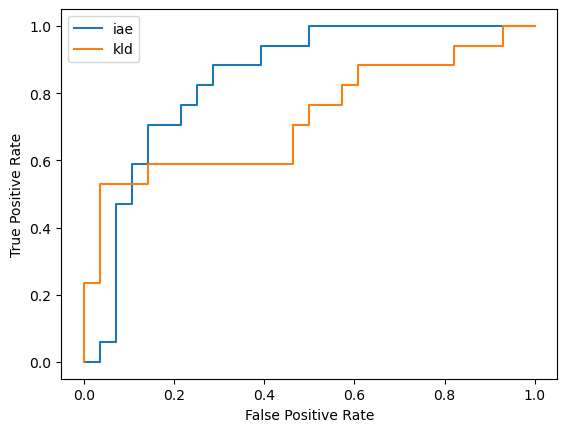

In [143]:
fpr, tpr, thresholds = roc_curve(merged_ci_tables["dependence"], merged_ci_tables["iae"])
plt.plot(fpr, tpr, label="iae")
fpr, tpr, thresholds = roc_curve(merged_ci_tables["dependence"], merged_ci_tables["kld"])
plt.plot(fpr, tpr, label="kld")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()